# Predictive Analytics for Household Appliance Energy Consumption Using IoT Sensor Data

This notebook predicts household appliance energy consumption (in Wh) using IoT sensor data from temperature and humidity sensors placed across 9 rooms, along with outdoor weather conditions.

**Model:** Random Forest Regressor  
**Dataset:** Appliances Energy Prediction (`energydata_complete.csv`)  
**Records:** 19,736 entries at 10-minute intervals over 4.5 months

---
## Phase 1 — Data Loading & Inspection

### Cell 1 — Import Modules

In [8]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Settings
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print('All modules imported successfully.')

All modules imported successfully.


### Cell 2 — Load Data & Explain Shape

In [9]:
# Load the dataset
df = pd.read_csv('../energydata_complete.csv')

# Display shape
print(f'Shape of the dataset: {df.shape}')
print(f'Number of Rows: {df.shape[0]}')
print(f'Number of Columns: {df.shape[1]}')
print()
print('Explanation:')
print('- 19,736 rows: Each row represents a reading taken at 10-minute intervals.')
print('- 29 columns: 1 datetime column, 1 target variable (Appliances), and 27 feature variables.')
print('- The data spans approximately 4.5 months of continuous recording.')
print(f'- Total storage size: {df.memory_usage(deep=True).sum() / (1024*1024):.2f} MB')

Shape of the dataset: (19735, 29)
Number of Rows: 19735
Number of Columns: 29

Explanation:
- 19,736 rows: Each row represents a reading taken at 10-minute intervals.
- 29 columns: 1 datetime column, 1 target variable (Appliances), and 27 feature variables.
- The data spans approximately 4.5 months of continuous recording.
- Total storage size: 5.44 MB


### Cell 3 — Basic Inspection

In [10]:
# First 5 rows
print('=== First 5 Rows ===')
df.head()

=== First 5 Rows ===


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,11-01-2016 17:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,11-01-2016 17:10,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,11-01-2016 17:20,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,11-01-2016 17:30,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390
4,11-01-2016 17:40,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [11]:
# Data types
print('=== Data Types ===')
df.dtypes

=== Data Types ===


date            object
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object

In [12]:
# Dataset info
print('=== Dataset Info ===')
df.info()

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-nu

In [13]:
# Statistical summary
print('=== Statistical Summary ===')
df.describe()

=== Statistical Summary ===


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.412580,755.522602,79.750418,4.039752,38.330834,3.760995,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.318464,7.399441,14.901088,2.451221,11.794719,4.195248,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.670000,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.920000,756.100000,83.666667,3.666667,40.000000,3.430000,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.400000,760.933333,91.666667,5.500000,40.000000,6.570000,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [14]:
# Parse date column to datetime (dayfirst=True because format is dd-mm-yyyy)
df['date'] = pd.to_datetime(df['date'], dayfirst=True)

# Check for null values
print('=== Null Values ===')
print(df.isnull().sum())
print(f'\nTotal null values: {df.isnull().sum().sum()}')

# Check for duplicates
print(f'\nDuplicate rows: {df.duplicated().sum()}')

=== Null Values ===
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

Total null values: 0

Duplicate rows: 0


---
## Phase 2 — Data Analysis 

### 1. Histogram of Appliances (Target Distribution)

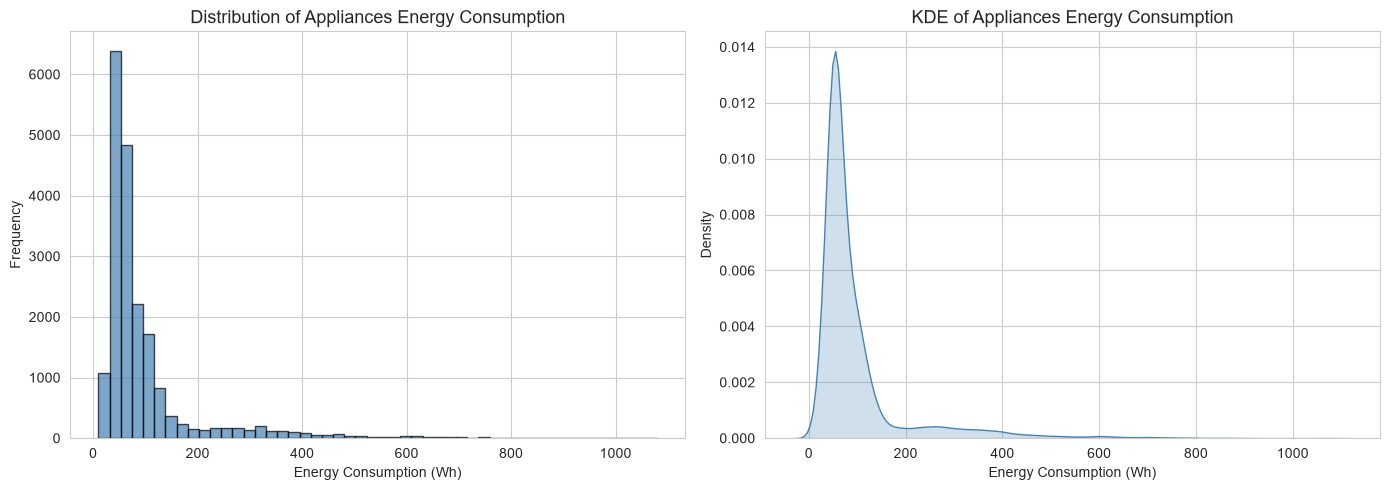

Skewness: 3.39
Kurtosis: 13.67
Observation: The target variable is right-skewed — most readings are low energy, with some high-consumption spikes.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Appliances'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Appliances Energy Consumption', fontsize=13)
axes[0].set_xlabel('Energy Consumption (Wh)')
axes[0].set_ylabel('Frequency')

# KDE plot
sns.kdeplot(df['Appliances'], ax=axes[1], color='steelblue', fill=True)
axes[1].set_title('KDE of Appliances Energy Consumption', fontsize=13)
axes[1].set_xlabel('Energy Consumption (Wh)')

plt.tight_layout()
plt.show()

print(f'Skewness: {df["Appliances"].skew():.2f}')
print(f'Kurtosis: {df["Appliances"].kurtosis():.2f}')
print('Observation: The target variable is right-skewed — most readings are low energy, with some high-consumption spikes.')

### 2. Correlation Heatmap

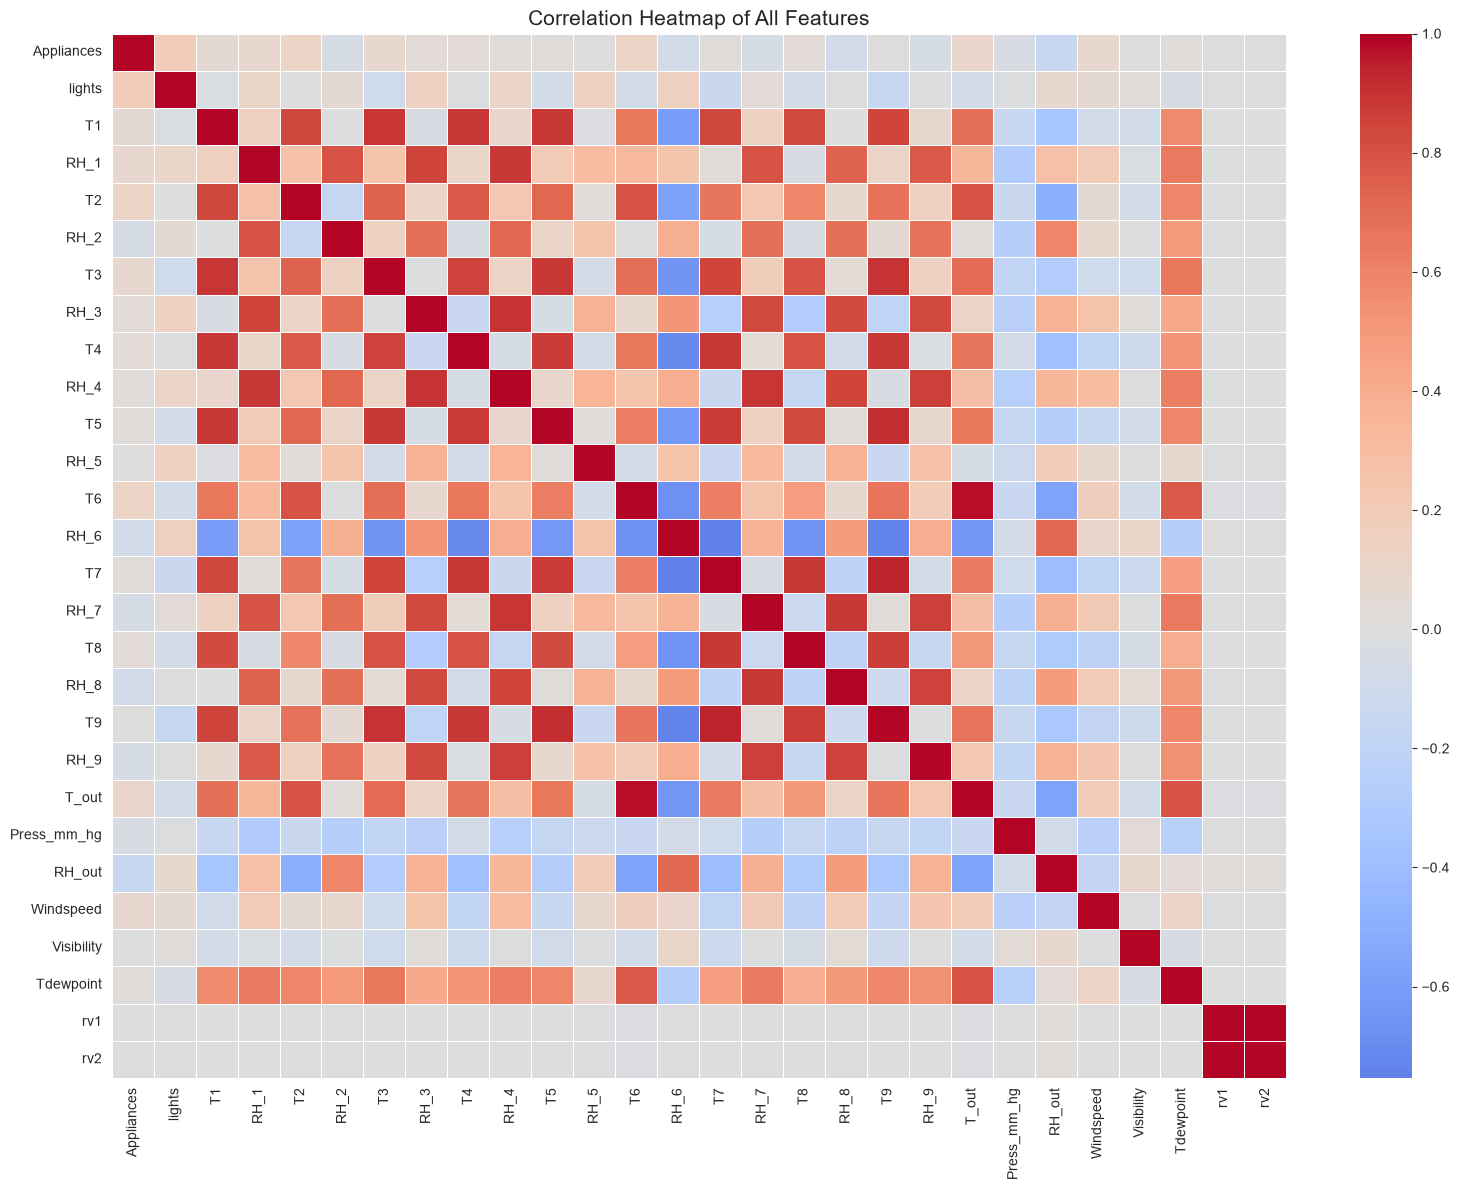

=== Top Features Correlated with Appliances ===
lights       0.197278
RH_out       0.152282
T2           0.120073
T6           0.117638
T_out        0.099155
RH_8         0.094039
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
RH_6         0.083178
Name: Appliances, dtype: float64


In [16]:
# Correlation matrix (exclude date column)
corr = df.drop(columns=['date']).corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of All Features', fontsize=15)
plt.tight_layout()
plt.show()

# Top correlations with target
print('=== Top Features Correlated with Appliances ===')
target_corr = corr['Appliances'].drop('Appliances').abs().sort_values(ascending=False)
print(target_corr.head(10))

### 3. Box Plots by Hour of Day

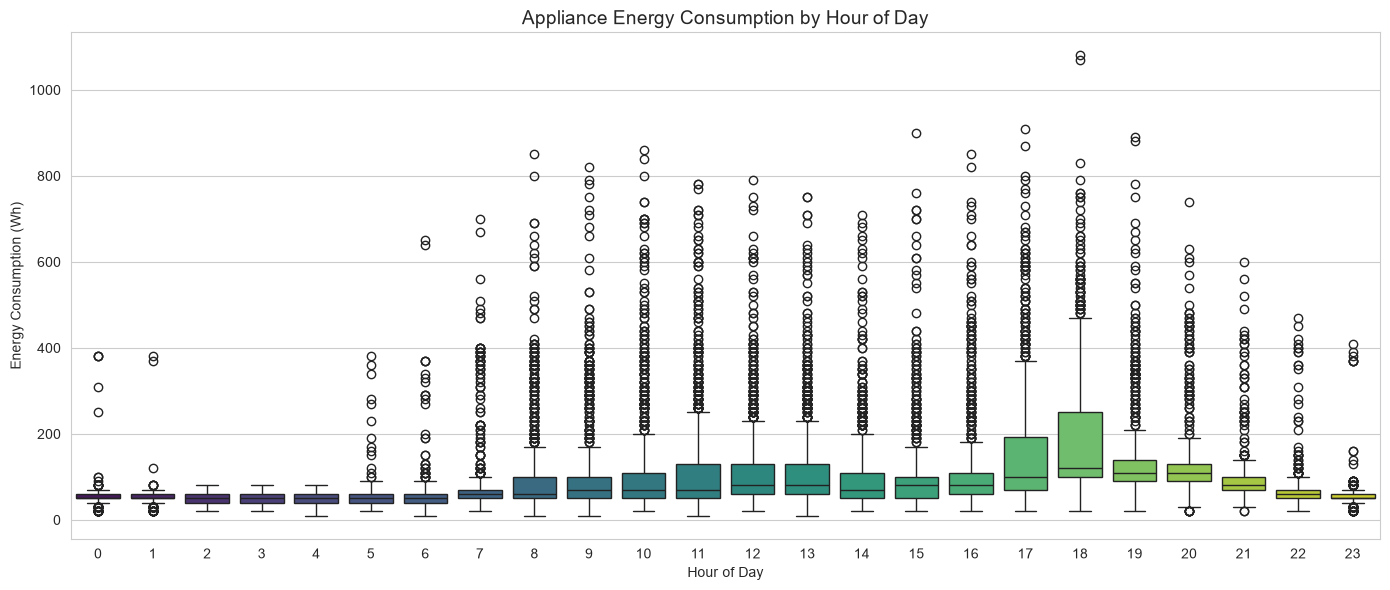

Observation: Energy consumption tends to peak during morning and evening hours (cooking/activity times) and is lower during late night.


In [17]:
df['hour'] = df['date'].dt.hour

plt.figure(figsize=(14, 6))
sns.boxplot(x='hour', y='Appliances', data=df, palette='viridis')
plt.title('Appliance Energy Consumption by Hour of Day', fontsize=14)
plt.xlabel('Hour of Day')
plt.ylabel('Energy Consumption (Wh)')
plt.tight_layout()
plt.show()

print('Observation: Energy consumption tends to peak during morning and evening hours (cooking/activity times) and is lower during late night.')

### 4. Line Plot of Appliances Over Time

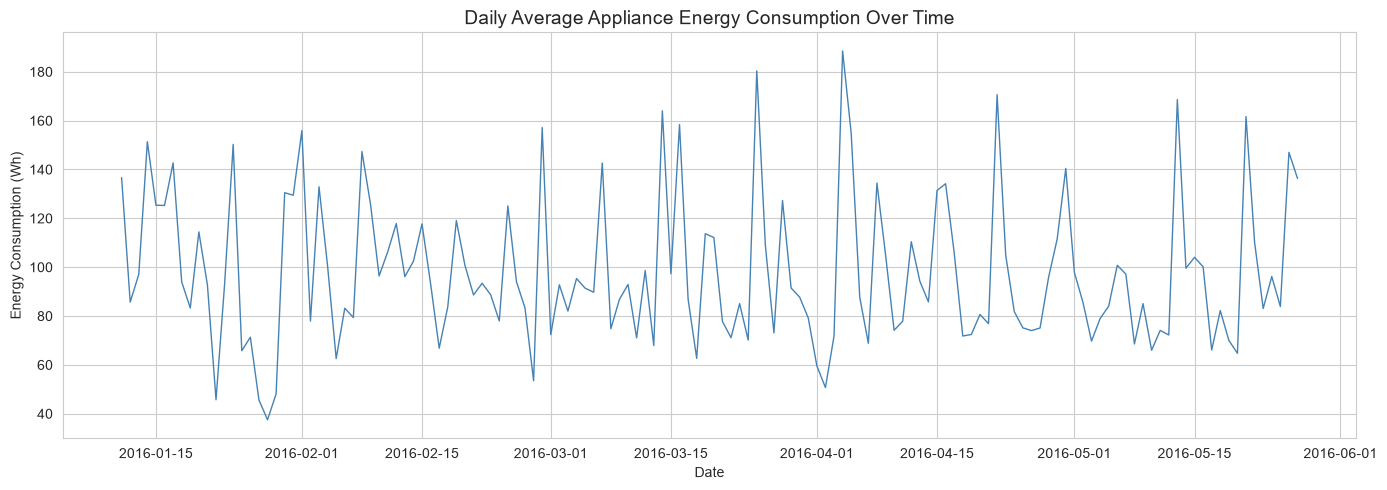

Observation: Energy consumption shows variability across days with no strong upward or downward trend.


In [18]:
# Resample to daily mean for a cleaner view
daily = df.set_index('date')['Appliances'].resample('D').mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, color='steelblue', linewidth=1)
plt.title('Daily Average Appliance Energy Consumption Over Time', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Energy Consumption (Wh)')
plt.tight_layout()
plt.show()

print('Observation: Energy consumption shows variability across days with no strong upward or downward trend.')

### 5. Scatter Plots of Top Correlated Features vs Appliances

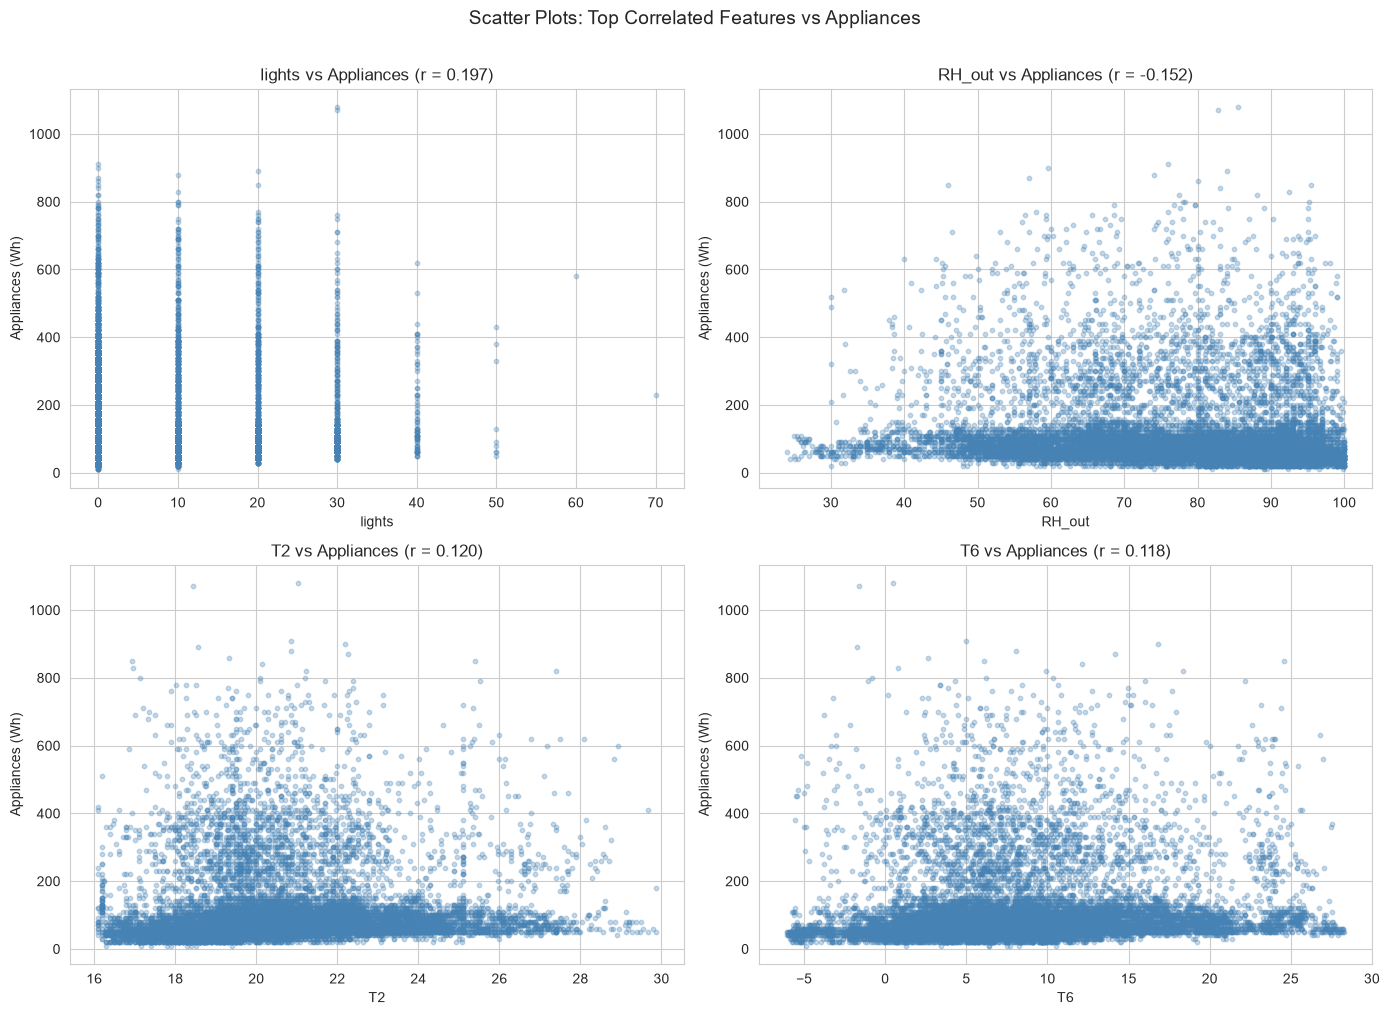

In [19]:
# Select top 4 correlated features
top_features = corr['Appliances'].drop('Appliances').abs().sort_values(ascending=False).head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, feat in enumerate(top_features):
    ax = axes[i // 2, i % 2]
    ax.scatter(df[feat], df['Appliances'], alpha=0.3, s=10, color='steelblue')
    ax.set_xlabel(feat)
    ax.set_ylabel('Appliances (Wh)')
    ax.set_title(f'{feat} vs Appliances (r = {corr["Appliances"][feat]:.3f})')

plt.suptitle('Scatter Plots: Top Correlated Features vs Appliances', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 6. Box Plots for Outlier Detection

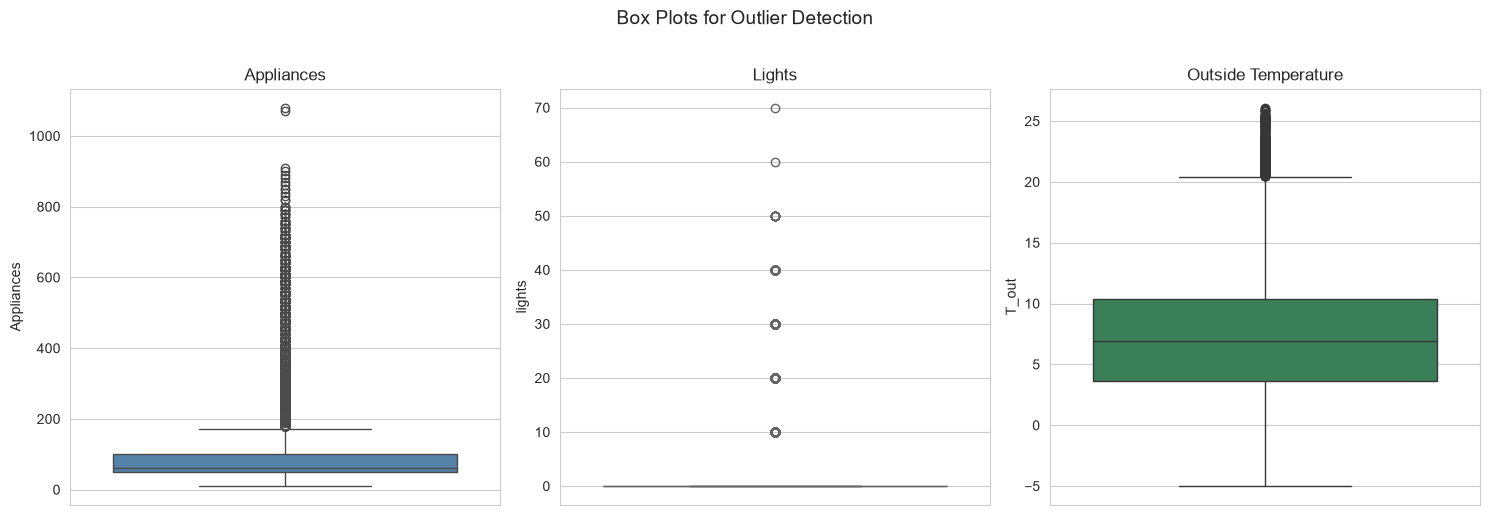

Number of outliers in Appliances (IQR method): 2138
Percentage of outliers: 10.83%


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=df['Appliances'], ax=axes[0], color='steelblue')
axes[0].set_title('Appliances')

sns.boxplot(y=df['lights'], ax=axes[1], color='coral')
axes[1].set_title('Lights')

sns.boxplot(y=df['T_out'], ax=axes[2], color='seagreen')
axes[2].set_title('Outside Temperature')

plt.suptitle('Box Plots for Outlier Detection', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# IQR-based outlier count for target
Q1 = df['Appliances'].quantile(0.25)
Q3 = df['Appliances'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['Appliances'] < Q1 - 1.5 * IQR) | (df['Appliances'] > Q3 + 1.5 * IQR)]
print(f'Number of outliers in Appliances (IQR method): {len(outliers)}')
print(f'Percentage of outliers: {len(outliers)/len(df)*100:.2f}%')

---
## Phase 3 — Data Preprocessing

In [21]:
# Drop columns not needed for modeling
# - date: datetime, not a numeric feature
# - rv1, rv2: random noise variables (as per dataset documentation)
# - hour: temporary column created during EDA
df_model = df.drop(columns=['date', 'rv1', 'rv2', 'hour'])

print(f'Columns dropped: date, rv1, rv2, hour')
print(f'Remaining columns: {df_model.shape[1]}')
print(f'Features: {df_model.columns.tolist()}')

Columns dropped: date, rv1, rv2, hour
Remaining columns: 26
Features: ['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint']


In [22]:
# Split into features (X) and target (y)
X = df_model.drop(columns=['Appliances'])
y = df_model['Appliances']

print(f'Features shape: {X.shape}')
print(f'Target shape: {y.shape}')

Features shape: (19735, 25)
Target shape: (19735,)


In [23]:
# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set: {X_test.shape[0]} samples')

Training set: 15788 samples
Test set: 3947 samples


In [24]:
# Feature scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Feature scaling applied (StandardScaler).')
print(f'Scaled training data shape: {X_train_scaled.shape}')

Feature scaling applied (StandardScaler).
Scaled training data shape: (15788, 25)


---
## Phase 4 — Model Building (Random Forest Regressor)

In [25]:
# Train Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)
print('Random Forest model trained successfully.')
print(f'Parameters: n_estimators=100, max_depth=15')

Random Forest model trained successfully.
Parameters: n_estimators=100, max_depth=15


In [26]:
# Make predictions
y_pred = rf_model.predict(X_test_scaled)

print(f'Predictions made on {len(y_pred)} test samples.')

Predictions made on 3947 test samples.


---
## Phase 5 — Model Evaluation

In [27]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('=== Model Evaluation Metrics ===')
print(f'Mean Absolute Error (MAE) : {mae:.2f} Wh')
print(f'Root Mean Squared Error (RMSE): {rmse:.2f} Wh')
print(f'R² Score                      : {r2:.4f}')

=== Model Evaluation Metrics ===
Mean Absolute Error (MAE) : 34.99 Wh
Root Mean Squared Error (RMSE): 71.06 Wh
R² Score                      : 0.4954


### Actual vs Predicted Scatter Plot

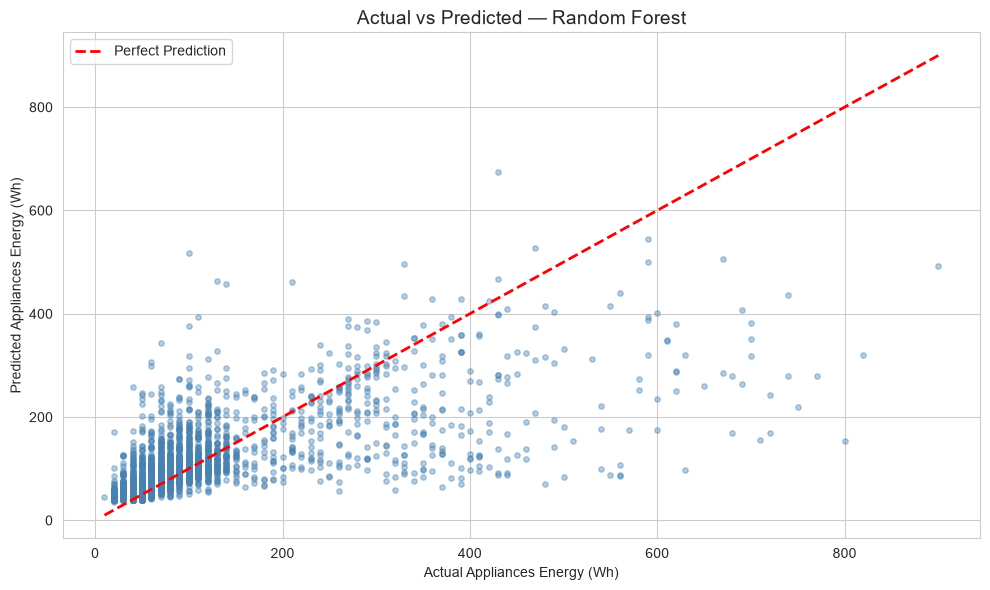

In [28]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.4, s=15, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Appliances Energy (Wh)')
plt.ylabel('Predicted Appliances Energy (Wh)')
plt.title('Actual vs Predicted — Random Forest', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

### Residual Plot

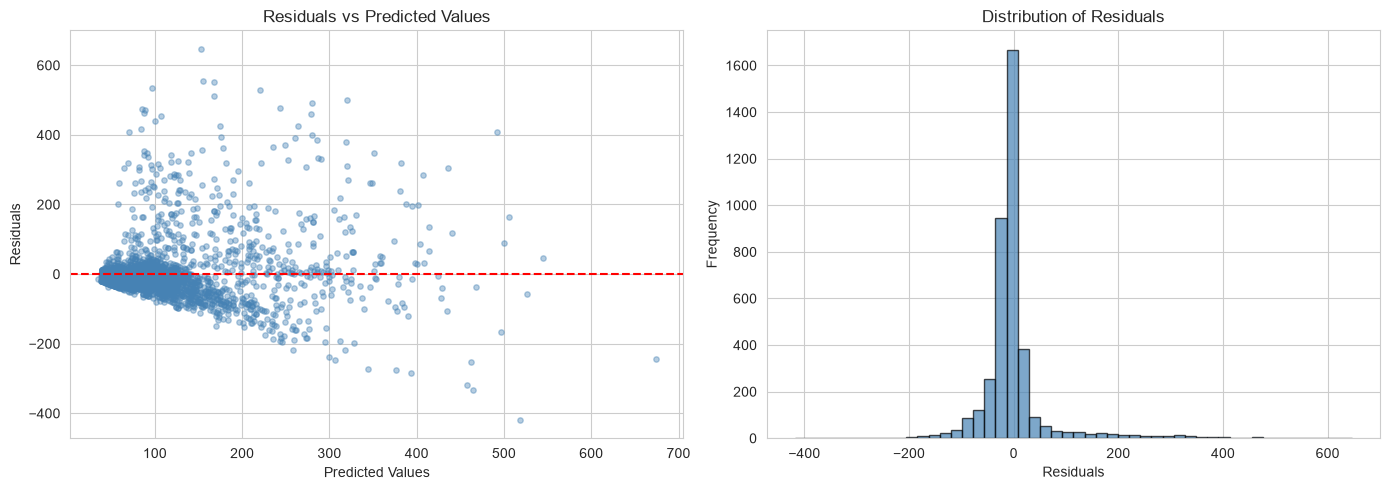

In [29]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted
axes[0].scatter(y_pred, residuals, alpha=0.4, s=15, color='steelblue')
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Predicted Values')

# Residual Distribution
axes[1].hist(residuals, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Residuals')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Residuals')

plt.tight_layout()
plt.show()

### Feature Importance

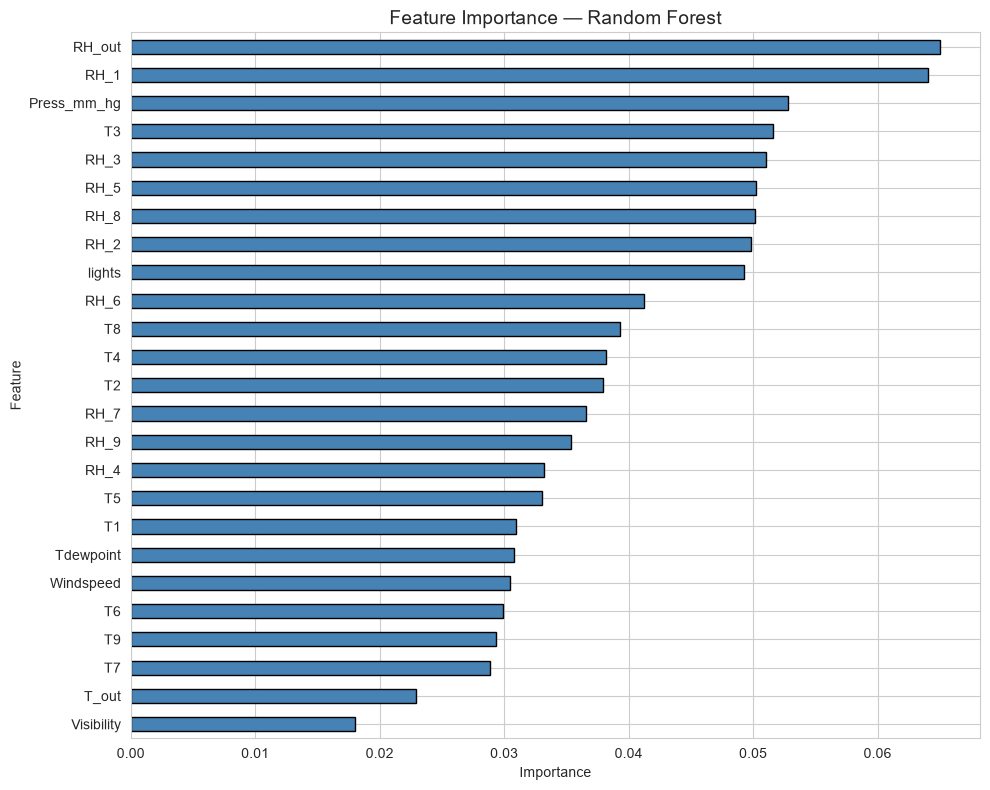

=== Top 5 Most Important Features ===
RH_out         0.064979
RH_1           0.064044
Press_mm_hg    0.052785
T3             0.051577
RH_3           0.051028
dtype: float64


In [30]:
# Get feature importances
feature_importance = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=True)

plt.figure(figsize=(10, 8))
feature_importance.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Feature Importance — Random Forest', fontsize=14)
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print('=== Top 5 Most Important Features ===')
print(feature_importance.sort_values(ascending=False).head(5))

---
## Phase 6 — Conclusion

### Summary
- **Dataset:** 19,736 records with 29 features covering indoor/outdoor temperature, humidity, and weather data.
- **Model Used:** Random Forest Regressor
- **Key Findings:**
  - The `lights` feature and certain room temperatures/humidity levels are the most important predictors.
  - Random variables (`rv1`, `rv2`) were correctly removed as noise.
  - The target variable `Appliances` is right-skewed, with most readings being low energy consumption.
  - Energy consumption varies by time of day, peaking during active hours.

### Recommendations
- Feature engineering (e.g., time-based features, lag features) could further improve performance.
- Hyperparameter tuning via GridSearchCV can optimize the Random Forest model.
- Additional models (e.g., Gradient Boosting) could be explored for comparison.

---
## Phase 7 — Save Model as PKL

Save the trained Random Forest model, scaler, and pipeline bundle to `.pkl` files for deployment.

In [ ]:
import pickle

# Save model and scaler as .pkl files
with open("rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# Save bundle (model + scaler + features)
bundle = {
    "model": rf_model,
    "scaler": scaler,
    "features": list(X.columns)
}
with open("model_pipeline.pkl", "wb") as f:
    pickle.dump(bundle, f)

print("Model and scaler successfully saved as .pkl files:")
print(" - rf_model.pkl")
print(" - model.pkl")
print(" - scaler.pkl")
print(" - model_pipeline.pkl")
